In [1]:
%% MIT 18.03 Lecture 28: Laplace Transform III, s-Derivative & Completing the Square
% Description: Demonstrates advanced Laplace methods using Control System Toolbox:
%              1) Repeated-root partial fractions for ramp IVP: x'_r + 2x = 4t, x(0+) = 1.
%              2) s-Derivative rule validation: L^{-1}{ 2*w*s / (s^2 + w^2)^2 } = t*sin(w*t).
%              3) Completing the square for 2nd-order impulse response: W(s) = 1/(s^2 + 2s + 2).
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, impulse, pole).
%
% % MBD Concept Mapping: Connects repeated s-domain poles at origin to ramp steady-state error,
% %                      repeated imaginary poles to secular resonance via the s-derivative rule,
% %                      and completing the square to underdamped modal pole coordinates (-sigma +/- j*wd).


clear; clc; close all;


%% =========================================================================
%% Part 1: Ramp Input IVP & Repeated-Root Partial Fractions (Section [2])
%% =========================================================================
% Equation: x'_r + 2x = 4t, x(0+) = 1
% s-Domain: (s + 2)*X(s) = 4/s^2 + 1  -->  X(s) = (s^2 + 4) / (s^2 * (s + 2))
s = tf('s');


% Construct common-denominator rational function for total response
num_ramp = [1, 0, 4];               % s^2 + 4
den_ramp = conv([1, 2], [1, 0, 0]); % (s + 2) * s^2 = s^3 + 2s^2
X_ramp_tf = tf(num_ramp, den_ramp);


% Partial fraction expansion via MATLAB 'residue'
% For repeated root s = 0, residue returns coefficients for c/(s+2), a/s, and b/s^2
[r_ramp, p_ramp, ~] = residue(num_ramp, den_ramp);


fprintf('=== MIT 18.03 Lecture 28 Partial Fractions & Pole Diagnostics ===\n');

=== MIT 18.03 Lecture 28 Partial Fractions & Pole Diagnostics ===

In [2]:
fprintf('1) Ramp IVP: X(s) = (s^2 + 4) / (s^2 * (s + 2))\n');

1) Ramp IVP: X(s) = (s^2 + 4) / (s^2 * (s + 2))

In [3]:
for idx = 1:length(p_ramp)
    fprintf('   Pole p = %+.2f  -->  Residue / Coefficient = %+.4f\n', p_ramp(idx), r_ramp(idx));
end

   Pole p = -2.00  -->  Residue / Coefficient = +2.0000
   Pole p = +0.00  -->  Residue / Coefficient = -1.0000
   Pole p = +0.00  -->  Residue / Coefficient = +2.0000

In [4]:
fprintf('   Analytical Match: c = +2/(s+2), a = -1/s, b = +2/s^2\n\n');

   Analytical Match: c = +2/(s+2), a = -1/s, b = +2/s^2

In [5]:


t_eval = linspace(0, 4.0, 800);
[x_ramp_sim, ~] = impulse(X_ramp_tf, t_eval);
x_ramp_exact    = -1.0 + 2.0 * t_eval + 2.0 * exp(-2.0 * t_eval);
x_asymptote     = -1.0 + 2.0 * t_eval; % Steady-state ramp tracking with constant lag -1


%% =========================================================================
%% Part 2: s-Derivative Rule & Completing the Square (Sections [3] & [4])
%% =========================================================================
% Section [3]: L[t * sin(w*t)] = -d/ds [ w / (s^2 + w^2) ] = 2*w*s / (s^2 + w^2)^2
w0 = 3.0;
F_s_deriv = (2 * w0 * s) / ((s^2 + w0^2)^2);


t_res = linspace(0, 6.0, 800);
[y_s_deriv_sim, ~] = impulse(F_s_deriv, t_res);
y_s_deriv_exact    = t_res .* sin(w0 * t_res);


% Section [4]: w'' + 2w' + 2w = delta(t)  -->  W(s) = 1 / (s^2 + 2s + 2) = 1 / ((s+1)^2 + 1)
W_2nd_tf = 1 / (s^2 + 2*s + 2);
[w_2nd_sim, ~] = impulse(W_2nd_tf, t_res);
w_2nd_exact    = exp(-t_res) .* sin(t_res);


fprintf('2) Second-Order Impulse Response: W(s) = 1 / (s^2 + 2s + 2)\n');

2) Second-Order Impulse Response: W(s) = 1 / (s^2 + 2s + 2)

In [6]:
poles_2nd = pole(W_2nd_tf);
fprintf('   Completed Square Form: 1 / ((s + 1)^2 + 1^2)\n');

   Completed Square Form: 1 / ((s + 1)^2 + 1^2)

In [7]:
fprintf('   Extracted Poles      : %+.2f %+.2fi, %+.2f %+.2fi\n', ...
        real(poles_2nd(1)), imag(poles_2nd(1)), real(poles_2nd(2)), imag(poles_2nd(2)));

   Extracted Poles      : -1.00 +1.00i, -1.00 -1.00i

In [8]:
fprintf('=================================================================\n');


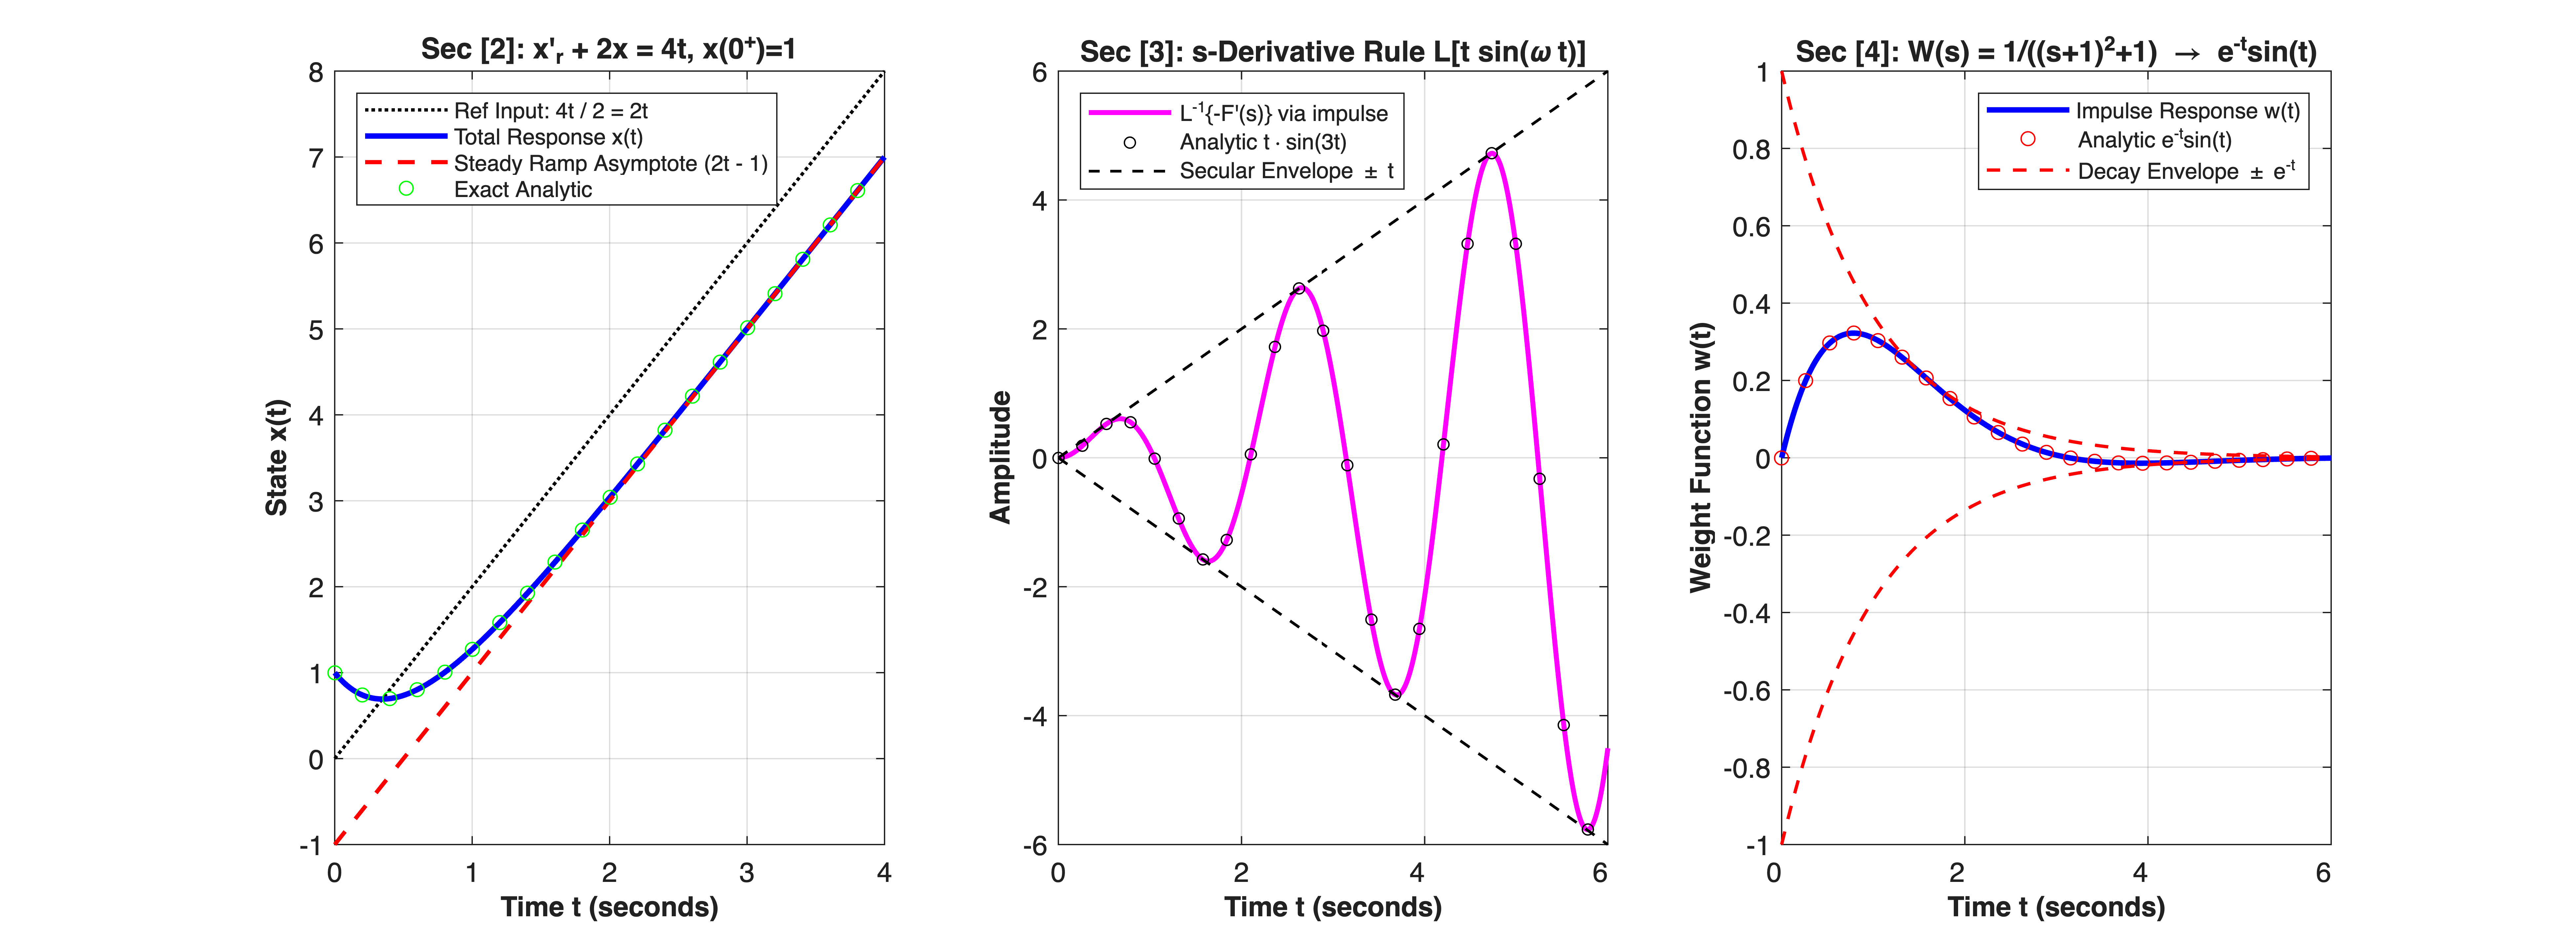

In [9]:


%% =========================================================================
%% Part 3: Multi-Panel Engineering Visualization
%% =========================================================================
figure('Color', [1 1 1], 'Position', [80, 80, 1250, 460]);


% Subplot 1: Ramp IVP & Steady-State Lag Asymptote
subplot(1, 3, 1);
hold on; grid on; box on;
plot(t_eval, 2 * t_eval, 'k:', 'LineWidth', 1.2, 'DisplayName', 'Ref Input: 4t / 2 = 2t');
plot(t_eval, x_ramp_sim, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Total Response x(t)');
plot(t_eval, x_asymptote, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Steady Ramp Asymptote (2t - 1)');
plot(t_eval(1:40:end), x_ramp_exact(1:40:end), 'go', 'MarkerSize', 5, 'DisplayName', 'Exact Analytic');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title("Sec [2]: x'_r + 2x = 4t, x(0^+)=1", 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);


% Subplot 2: s-Derivative Rule (Secular Resonance Generation)
subplot(1, 3, 2);
hold on; grid on; box on;
plot(t_res, y_s_deriv_sim, 'm-', 'LineWidth', 1.8, 'DisplayName', 'L^{-1}\{-F''(s)\} via impulse');
plot(t_res(1:35:end), y_s_deriv_exact(1:35:end), 'ko', 'MarkerSize', 4, 'DisplayName', 'Analytic t\cdotsin(3t)');
plot(t_res, t_res, 'k--', 'LineWidth', 1.0, 'DisplayName', 'Secular Envelope \pm t');
plot(t_res, -t_res, 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [3]: s-Derivative Rule L[t sin(\omega t)]', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);


% Subplot 3: Second-Order Completing the Square Impulse Response
subplot(1, 3, 3);
hold on; grid on; box on;
plot(t_res, w_2nd_sim, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Impulse Response w(t)');
plot(t_res(1:35:end), w_2nd_exact(1:35:end), 'ro', 'MarkerSize', 5, 'DisplayName', 'Analytic e^{-t}sin(t)');
plot(t_res, exp(-t_res), 'r--', 'LineWidth', 1.2, 'DisplayName', 'Decay Envelope \pm e^{-t}');
plot(t_res, -exp(-t_res), 'r--', 'LineWidth', 1.2, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Weight Function w(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [4]: W(s) = 1/((s+1)^2+1) \rightarrow e^{-t}sin(t)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8);